In [1]:
# Patch for matplotlib_inline 0.2.2 incompatibility with newer matplotlib (see the hls4ml export notebook).
import matplotlib
if not hasattr(matplotlib.rcParams, "_get"):
    matplotlib.rcParams._get = matplotlib.rcParams.__getitem__

# Quantization-aware training with HGQ2 → hls4ml → Vitis HLS

This notebook goes from nothing to a synthesised FPGA design, with a **hexagonal CNN whose bit widths are learned**:

```
toy hex images ──► float CNN (reference)
       │
       └─► QAT CNN (QConv2d / QMaxPool2d + HGQ2's QDense, HGQ2 quantizers)
                │  trained with  loss + β · EBOPs   (the bit widths shrink where the task allows)
                ▼
          freeze()  ──►  plain hex layers holding the quantized values, the quantizers kept as layers
                ▼
          patch_model_for_hls()
                ▼
          hls4ml  ──►  derives every type itself (bit-exact flow)  ──►  C simulation: equal to Keras
                                                                  ──►  Vitis HLS synthesis (LUT / FF / DSP / latency)
```

Why bother: a hex convolution costs, per pixel, `7 taps × C_in × C_out` multiplications. Their cost on an FPGA
grows with the **bit widths** of the weights and activations, so letting the training find the narrowest
widths that still work is the cheapest way to shrink the design.

**What is quantized:** everything: the hexagonal layers (`QConv2d`, `QMaxPool2d`: weights, bias, input and
output) and the dense head, with HGQ2's own `QDense`. Both kinds of layer live in the same model, are
counted together in the EBOPs, and are exported together: hls4ml derives every type of the design from the
input quantizer and the values of the weights, so there is **no type to write by hand**.

**Requirements:** `pip install keras-hexagdly[qat] hls4ml` (HGQ2 needs Python ≥ 3.10) and, for the last
section, Vitis HLS (the C simulation only needs `g++`). Use the TensorFlow or torch Keras backend
(the hls4ml export is not available with JAX).

In [2]:
import os, shutil, stat, sys, tempfile

import numpy as np
import matplotlib.pyplot as plt
import keras

import hls4ml
from hgq.layers import QDense
from hgq.quantizer import QuantizerConfig
from hgq.utils.sugar import BetaScheduler, FreeEBOPs, PieceWiseSchedule

import keras_hexagdly as hgly
from keras_hexagdly.hls4ml_ext import hex_reuse_config, patch_model_for_hls
from keras_hexagdly.hls4ml_handler import register_hex_gather_layers

# toy data shared with the other notebooks
sys.path.insert(0, os.getcwd())
from toy_data import ToyDataset

print("keras", keras.__version__, "| backend", keras.backend.backend())
keras.utils.set_random_seed(0)

2026-10-24 19:24:10.400181: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-24 19:24:10.400420: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-24 19:24:10.431471: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


keras 3.12.0 | backend tensorflow


## 1. Data and a float reference

Four hexagonal shapes on a 10×10 offset grid (the layout `keras-hexagdly` uses). A float CNN is trained
first: it is the accuracy to keep, and the design to beat in section 7.

In [3]:
shape_list = ["snowflake_2", "snowflake_3", "snowflake_4", "double_hex"]
H = W = 10
x_train, y_train = ToyDataset(shape_list, 128, H, W).create(seed=0).to_arrays()
x_val, y_val = ToyDataset(shape_list, 32, H, W).create(seed=1).to_arrays()
print("train", x_train.shape, " val", x_val.shape)


def float_cnn():
    inp = keras.Input((H, W, 1), name="image")
    x = hgly.Conv2d(8, kernel_size=2, share_neighbors=True, activation="relu", name="conv1")(inp)
    x = hgly.MaxPool2d(kernel_size=1, strides=2, name="pool1")(x)
    x = hgly.Conv2d(4, kernel_size=1, share_neighbors=True, activation="relu", name="conv2")(x)
    x = keras.layers.Flatten(name="flat")(x)
    x = keras.layers.Dense(16, activation="relu", name="fc1")(x)
    out = keras.layers.Dense(len(shape_list), name="logits")(x)
    return keras.Model(inp, out, name="float_hex_cnn")


def compile_model(m):
    m.compile(
        keras.optimizers.Adam(3e-3),
        keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"],
    )


float_model = float_cnn()
compile_model(float_model)
float_model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=150, batch_size=32, verbose=0)
float_acc = float_model.evaluate(x_val, y_val, verbose=0)[1]
print(f"float model: validation accuracy {float_acc:.3f}")

train (512, 10, 10, 1)  val (128, 10, 10, 1)


E0000 00:00:1792862653.847853 2396344 cuda_executor.cc:1309] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1792862653.856231 2396344 gpu_device.cc:2342] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


float model: validation accuracy 0.969


## 2. The QAT model

`QConv2d`, `QMaxPool2d`… are the hexagonal layers with [HGQ2](https://github.com/calad0i/HGQ2) quantizers
switched on one by one:

| argument | what it quantizes |
|---|---|
| `kq_conf` | the kernel (each sub-kernel of the hexagonal decomposition has its own quantizer) |
| `bq_conf` | the bias |
| `iq_conf` | the layer input |
| `oq_conf` | the layer output, **after** the activation |

Two choices here come from the hardware export:

* the **weights** get one learned bit width **per element** (`trainable=True`, the default): a weight that
  reaches 0 bit is pruned;
* each tensor is quantized **once**: the `iq_conf` of the layer that reads it, and no `oq_conf` on the layer
  that produces it (the one exception: the output of the model). Two quantizers in a row are merged by
  hls4ml into one type, and the double rounding of Keras can then differ from it by a step;
* the **activations** get one bit width **per layer** (`homogeneous_axis=(0, 1, 2, 3)` for an image,
  `(0, 1)` for the flat tensors of the dense head), because hls4ml's `io_stream` has one type per tensor.

The input images are 0/1 here, so the first input quantizer is unsigned (`signed=0`), and so are the others:
every tensor is the output of a ReLU or a max pooling. The model input must be quantized (the first
`iq_conf`): hls4ml starts from it.

In [4]:
def per_layer(ints, fracs, signed=1, axes=(0, 1, 2, 3)):
    """An activation quantizer with one learned bit width for the whole layer (sign + ints + fracs)."""
    return QuantizerConfig(
        "kif", "datalane", k0=signed, i0=ints, f0=fracs,
        overflow_mode="SAT", round_mode="RND", homogeneous_axis=axes,
    )


# weights: sign + 1 integer bit + 7 fractional bits at the start, learned per element afterwards
weights = QuantizerConfig("kbi", "weight", k0=1, b0=8, i0=2)


def qat_cnn():
    inp = keras.Input((H, W, 1), name="image")
    x = hgly.QConv2d(
        8, kernel_size=2, share_neighbors=True, activation="relu", name="conv1",
        kq_conf=weights, bq_conf=weights, iq_conf=per_layer(1, 4, signed=0),
    )(inp)
    x = hgly.QMaxPool2d(kernel_size=1, strides=2, name="pool1")(x)
    x = hgly.QConv2d(
        4, kernel_size=1, share_neighbors=True, activation="relu", name="conv2",
        kq_conf=weights, bq_conf=weights, iq_conf=per_layer(3, 4, signed=0),
    )(x)
    x = keras.layers.Flatten(name="flat")(x)
    x = QDense(
        16, activation="relu", name="fc1", kq_conf=weights, bq_conf=weights,
        iq_conf=per_layer(3, 4, signed=0, axes=(0, 1)),
    )(x)
    out = QDense(
        len(shape_list), name="logits", kq_conf=weights, bq_conf=weights,
        iq_conf=per_layer(4, 4, signed=0, axes=(0, 1)), oq_conf=per_layer(6, 3, axes=(0, 1)),  # the output
    )(x)
    return keras.Model(inp, out, name="qat_hex_cnn")


qat_model = qat_cnn()
compile_model(qat_model)
qat_model.summary()

Model: "qat_hex_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 10, 10, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (QConv2d)                 │ (None, 10, 10, 8)      │           133 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (QMaxPool2d)              │ (None, 5, 5, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (QConv2d)                 │ (None, 5, 5, 4)        │           277 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flat (Flatten)                  │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (QDense)                    │ (None, 16)             │         6,469 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (QDense)                 │ (None, 4)              │           277 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,156 (22.71 KB)

 Trainable params: 5,360 (20.94 KB)

 Non-trainable params: 1,796 (1.78 KB)

## 3. Training with EBOPs

A convolution that has an input quantizer, like HGQ2's own layers, counts its cost in **EBOPs** (effective bit operations: the bits
of each weight times the bits of the input it multiplies, summed over the hexagon, zero padding excluded, a
pruned weight costing nothing). During training the loss becomes `loss + β · EBOPs`: the larger β, the harder
the bit widths are pushed down.

Rather than a fixed β, a **schedule** lets the network learn the task first, then squeezes it:
β = 0 for 40 epochs, then a linear ramp to its final value `3e-7`. HGQ2's `FreeEBOPs` callback records the EBOPs
of every epoch (they are the sum over all the layers that count them: the two hexagonal convolutions and the two dense ones). `BetaPID` can instead aim at
a target EBOPs.

**Choosing β matters.** With the same network and data, `β = 3e-7` kept the accuracy on every seed tried,
while `β = 1e-6` and above sometimes pushed an input quantizer to 0 bit (the network then outputs a
constant: 25 % accuracy on four classes). Watch the validation accuracy next to the EBOPs, and lower β
if it falls.

QAT model: validation accuracy 0.992  (float: 0.969)
EBOPs: 838,080 at the start -> 215,775 at the end  (x3.9 fewer)


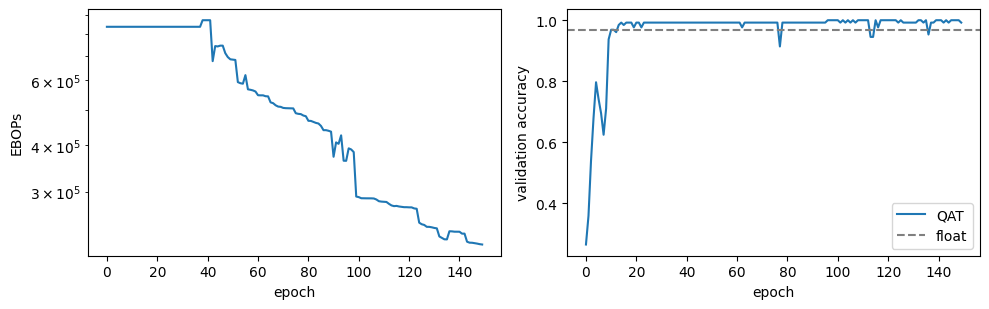

In [5]:
schedule = PieceWiseSchedule([(0, 0.0, "constant"), (40, 0.0, "linear"), (110, 3e-7, "constant")])
history = qat_model.fit(
    x_train, y_train, validation_data=(x_val, y_val), epochs=150, batch_size=32, verbose=0,
    callbacks=[FreeEBOPs(), BetaScheduler(schedule)],
)
qat_acc = qat_model.evaluate(x_val, y_val, verbose=0)[1]
ebops = history.history["ebops"]
print(f"QAT model: validation accuracy {qat_acc:.3f}  (float: {float_acc:.3f})")
print(f"EBOPs: {ebops[0]:,.0f} at the start -> {ebops[-1]:,.0f} at the end  (x{ebops[0] / ebops[-1]:.1f} fewer)")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(ebops); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("EBOPs"); ax[0].set_yscale("log")
ax[1].plot(history.history["val_accuracy"], label="QAT"); ax[1].axhline(float_acc, ls="--", c="gray", label="float")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()

## 4. What the training learned

Each hexagonal layer can tell the exact `ap_fixed<W,I>` type of its tensors, read from the values themselves
(not from the quantizer parameters, which are only a bound). The EBOPs left in each layer come after:

In [6]:
for name in ("conv1", "conv2"):
    layer = qat_model.get_layer(name)
    kernels = np.concatenate([w.ravel() for w in layer.quantized_weights()])
    print(f"{name}:")
    print(f"  weights  {layer.weight_type():>12}   ({np.mean(kernels == 0):.0%} of the weights are exactly 0)")
    print(f"  bias     {layer.bias_type():>12}")
    print(f"  input    {layer.input_type()}")
    print(f"  accumulator (exact) {layer.accum_type()}")
print()
for layer in qat_model.layers:
    if getattr(layer, "enable_ebops", False):
        print(f"EBOPs of {layer.name:<7}: {int(keras.ops.convert_to_numpy(layer.ebops)):>8,}")

conv1:
  weights  ap_fixed<7,2>   (42% of the weights are exactly 0)
  bias     ap_fixed<5,0>
  input    ap_ufixed<2,1,AP_RND,AP_SAT>
  accumulator (exact) ap_fixed<15,9>
conv2:
  weights  ap_fixed<9,2>   (42% of the weights are exactly 0)
  bias     ap_fixed<5,-1>
  input    ap_ufixed<4,2,AP_RND,AP_SAT>
  accumulator (exact) ap_fixed<20,11>

EBOPs of conv1  :   99,792
EBOPs of conv2  :   79,712
EBOPs of fc1    :   33,187
EBOPs of logits :    3,084


## 5. Freeze: from the training model to the deployment model

`freeze()` returns a new model in which every hexagonal quantized layer is back to its plain hexagonal layer
**holding the quantized values**. The activation quantizers stay in the model as standalone layers (HGQ2's
own layers are untouched), so the frozen model computes *exactly* what the QAT model computes. It does not
modify the trained model.

In [7]:
frozen, _ = hgly.freeze(qat_model)
print([type(layer).__name__ for layer in frozen.layers])
diff = float(np.max(np.abs(frozen.predict(x_val, verbose=0) - qat_model.predict(x_val, verbose=0))))
print(f"max |frozen - QAT| on the validation set: {diff:.2e}")
assert diff < 1e-4

['InputLayer', 'Quantizer', 'Conv2d', 'MaxPool2d', 'Quantizer', 'Conv2d', 'Flatten', 'QDense', 'QDense']


max |frozen - QAT| on the validation set: 0.00e+00


## 6. hls4ml: no type to give, C simulation

`patch_model_for_hls` rewrites the hexagonal layers for the FPGA (line-buffer kernels, see the export
notebook). The frozen model still holds HGQ2 quantizers, so hls4ml runs its **bit-exact flow**: starting from
the input quantizer it computes, layer by layer, the range of every value from the values of the weights, and
sets every type itself (result, weights, bias, accumulator). The exported hexagonal layers take part in it.
`hex_reuse_config` gives each hexagonal layer an explicit reuse factor.

In [8]:
register_hex_gather_layers("Vitis")
FPGA_PART = "xc7vx485tffg1927-2"   # XC7VX485T-2FFG1927C
CLOCK_NS = 5


def hls_config(patched, uniform_precision=None):
    config = hls4ml.utils.config_from_keras_model(patched, granularity="name", backend="Vitis")
    if uniform_precision is not None:  # the usual export of a float model: one precision everywhere
        config["Model"]["Precision"] = uniform_precision
    config["Model"]["Strategy"] = "Resource"
    hex_reuse_config(config, patched, verbose=False)
    return config


def convert(patched, config, directory):
    if os.path.exists(directory):
        shutil.rmtree(directory)
    return hls4ml.converters.convert_from_keras_model(
        patched, hls_config=config, backend="Vitis", io_type="io_stream",
        output_dir=directory, part=FPGA_PART, clock_period=CLOCK_NS,
    )


patched_qat = patch_model_for_hls(frozen)
hls_qat = convert(patched_qat, hls_config(patched_qat), os.path.join(tempfile.gettempdir(), "hls_qat_hex"))

print("types hls4ml derived (output of each layer):")
for name, node in hls_qat.graph.items():
    if node.class_name != "Input" and "Quantizer" not in node.class_name:
        print(f"  {name:<22}{node.get_output_variable().type.precision}")

types hls4ml derived (output of each layer):
  conv1_linebuffer      fixed<12,6,TRN,WRAP,0>
  conv1_activation      ufixed<11,5,TRN,WRAP,0>
  pool1_linebuffer      ufixed<4,2,RND,SAT,0>
  conv2_linebuffer      fixed<8,7,TRN,WRAP,0>
  conv2_activation      ufixed<3,3,RND,SAT,0>
  flat                  ufixed<3,3,RND,SAT,0>
  fc1                   fixed<12,8,TRN,WRAP,0>
  fc1_relu              ufixed<7,4,RND,SAT,0>
  logits                fixed<17,8,TRN,WRAP,0>


In [9]:
hls_qat.compile()
x_csim = np.ascontiguousarray(x_val[:64])
y_hls = hls_qat.predict(x_csim)
y_keras = qat_model.predict(x_csim, verbose=0)
print(f"C simulation vs the QAT Keras model: max |diff| of the logits = {np.max(np.abs(y_hls - y_keras)):.3g}")
print(f"C-simulation accuracy: {np.mean(np.argmax(y_hls, 1) == y_val[:64]):.3f}")
assert np.array_equal(y_hls, y_keras), "the C simulation should equal the Keras model exactly"

C simulation vs the QAT Keras model: max |diff| of the logits = 0
C-simulation accuracy: 1.000


The C simulation equals the Keras model **exactly**, with nothing set by hand: the layers that hls4ml
derives its types from are the quantizers you trained. (`tests/test_hls_bit_exact_csim.py` checks this on
every release.)

## 7. Vitis HLS synthesis, against a uniform-precision design

The fair comparison is the same float network exported the usual way: every weight and activation in
`ap_fixed<24,12>`. Both designs use the same part, clock, strategy and per-layer reuse factors.
The uniform precision is wide enough for the largest logits of the float model (`ap_fixed<16,6>` only
reaches ±32): a hand-tuned uniform precision, narrower per layer, would land between the two designs.

Synthesis takes a minute or so per design here and needs Vitis HLS (`hls4ml` still looks for `vivado_hls`: a one-line
shim to `vitis_hls` is created once).

In [10]:
VITIS_BIN = "/tools/Xilinx/Vitis_HLS/2024.2/bin"
os.environ["PATH"] = VITIS_BIN + ":" + os.environ.get("PATH", "")
shim = os.path.expanduser("~/.local/bin/vivado_hls")
if not os.path.isfile(shim):
    os.makedirs(os.path.dirname(shim), exist_ok=True)
    with open(shim, "w") as f:
        f.write(f"#!/bin/bash\nexec {VITIS_BIN}/vitis_hls \"$@\"\n")
    os.chmod(shim, os.stat(shim).st_mode | stat.S_IEXEC | stat.S_IXGRP | stat.S_IXOTH)

patched_float = patch_model_for_hls(float_model)
hls_float = convert(
    patched_float, hls_config(patched_float, "ap_fixed<24,12>"), os.path.join(tempfile.gettempdir(), "hls_float_hex")
)

for label, model in (("float, uniform <24,12>", hls_float), ("QAT, learned bit widths", hls_qat)):
    print("synthesising:", label)
    model.build(csim=False, synth=True, export=False)

synthesising: float, uniform <24,12>
[1 lines of the Vitis HLS log trimmed]


[8 lines of the Vitis HLS log trimmed]


[24 lines of the Vitis HLS log trimmed]


[11 lines of the Vitis HLS log trimmed]


[6 lines of the Vitis HLS log trimmed]


...

[23 lines of the Vitis HLS log trimmed]


[28 lines of the Vitis HLS log trimmed]


[1 lines of the Vitis HLS log trimmed]


INFO: [HLS 200-789] **** Estimated Fmax: 217.53 MHz
***** C/RTL SYNTHESIS COMPLETED IN 0h0m32s *****
[8 lines of the Vitis HLS log trimmed]


[5 lines of the Vitis HLS log trimmed]


In [11]:
def resources(model):
    """The csynth estimates of a synthesised model."""
    return hls4ml.report.parse_vivado_report(model.config.get_output_dir())["CSynthesisReport"]


rows = {"float, uniform <24,12>": resources(hls_float), "QAT, learned bit widths": resources(hls_qat)}
print(f"{'design':<26}{'LUT':>10}{'FF':>10}{'DSP':>8}{'BRAM_18K':>10}{'latency':>10}")
for label, r in rows.items():
    print(f"{label:<26}{r['LUT']:>10}{r['FF']:>10}{r['DSP']:>8}{r['BRAM_18K']:>10}{r['WorstLatency']:>10}")
print(f"\nvalidation accuracy: float {float_acc:.3f}, QAT {qat_acc:.3f}")

Vivado synthesis report not found.
Cosim report not found.
Timing report not found.
Vivado synthesis report not found.
Cosim report not found.
Timing report not found.
design                           LUT        FF     DSP  BRAM_18K   latency
float, uniform <24,12>         60266    189012    1642        45       171
QAT, learned bit widths        44958     21743     229        11       166

validation accuracy: float 0.969, QAT 0.992


These are Vitis HLS **estimates** after C synthesis (not place and route), for one small network, so read them as
an illustration, not as a benchmark. Narrower multiplications move from DSP blocks to LUTs, so compare the
whole picture (LUT, FF and DSP together) rather than one column. Vitis prints a few messages about an
`array_partition` option while it runs (a known mismatch between hls4ml's Vitis backend and Vitis 2024.2); the
synthesis completes and the reports above come from it.

## Going further

* **What the export needs.** The model input must be quantized (an `iq_conf` on the first layer, or start with
  an HGQ2 layer: `patch_model_for_hls` says so otherwise), and, for `io_stream`, one bit width per layer for
  the activation quantizers. The 3D layers and `QAvgPool2d` are not exported.
* **Setting the types by hand.** For a model whose other layers are plain Keras layers (a `Dense` head), or to
  choose the types yourself: `hgly.freeze(model, activation_quantizers="types")` returns the `ap_fixed` type of
  each tensor, and `apply_quantized_types(config, patched, types)` puts them in the hls4ml config
  (`accumulator="exact"` gives each convolution an accumulator that loses no bit).
* **Aim at a target.** Replace the schedule by `BetaPID(target_ebops=...)` to let HGQ2 tune β.
* **WRAP quantizers.** With `overflow_mode="WRAP"` call `hgq.utils.trace_minmax(model, data)` after training to
  find the integer bits the data needs.
* **Co-simulation.** Add `input_data_tb` / `output_data_tb` to `convert_from_keras_model` and call
  `model.build(cosim=True, validation=True)`, as in the hls4ml export notebook.